In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import jdatetime
import re


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


OUTPUT_FOLDER = Path("processed")
OUTPUT_FOLDER.mkdir(exist_ok=True)

In [2]:

products = pd.read_csv("Data/digikala-products.csv")
comments = pd.read_csv("Data/digikala-comments.csv")

C:\Users\Toranj\AppData\Local\Temp\ipykernel_9984\3463799615.py:1: DtypeWarning: Columns (0: Category2) have mixed types. Specify dtype option on import or set low_memory=False.
  products = pd.read_csv("Data/digikala-products.csv")


In [3]:
display(products.head())

,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,False,0,beauty
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,False,0,beauty
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,False,0,beauty
3,1912926,استند ابسلانگ مدل S01,78,25,آبسلانگ,NaN,متفرقه,1100000,بهراد طب بیدار,False,0,beauty
4,6335462,آبسلانگ نوری تسلامد مدل All-in-One,84,25,آبسلانگ,NaN,تسلا مد,1530000,دیجی‌کالا,False,0,beauty


In [4]:
display(comments.head())

,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN


In [5]:
print("products")
products.info()
print("\ncomments")
comments.info()


products
<class 'pandas.DataFrame'>
RangeIndex: 1283496 entries, 0 to 1283495
Data columns (total 12 columns):
 #   Column                Non-Null Count    Dtype
---  ------                --------------    -----
 0   id                    1283496 non-null  int64
 1   title_fa              1283496 non-null  str  
 2   Rate                  1283496 non-null  int64
 3   Rate_cnt              1283496 non-null  int64
 4   Category1             1283496 non-null  str  
 5   Category2             1073388 non-null  str  
 6   Brand                 1283496 non-null  str  
 7   Price                 1283496 non-null  int64
 8   Seller                1283273 non-null  str  
 9   Is_Fake               1283496 non-null  bool 
 10  min_price_last_month  1283496 non-null  int64
 11  sub_category          1283496 non-null  str  
dtypes: bool(1), int64(5), str(6)
memory usage: 312.0 MB

comments
<class 'pandas.DataFrame'>
RangeIndex: 6156289 entries, 0 to 6156288
Data columns (total 15 columns):
 #   C

In [6]:
display(products.describe(include="all").T)
display(comments.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,1283496.0,NaN,NaN,NaN,7948841.967717,3511631.292386,7602.0,5212286.0,8715048.0,11008907.0,12773763.0
title_fa,1283496,907314,تمبر یادگاری مدل خارجی مجموعه 6 عددی,145,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rate,1283496.0,NaN,NaN,NaN,30.13031,39.910976,0.0,0.0,0.0,80.0,100.0
Rate_cnt,1283496.0,NaN,NaN,NaN,20.738292,218.210075,0.0,0.0,0.0,2.0,30438.0
Category1,1283496,228,اکسسوری زنانه و مردانه,95999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category2,1073388,601,فکری و آموزشی,46767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,1283496,8961,متفرقه,723590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,1283496.0,NaN,NaN,NaN,8491273.41959,46632217.716447,0.0,700000.0,1560000.0,4450000.0,8499990000.0
Seller,1283273,18584,بوکم,26786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Is_Fake,1283496,2,False,1206033,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,6156289.0,NaN,NaN,NaN,37047085.584523,13932434.094475,981586.0,27312343.0,40447729.0,48971224.0,54745160.0
title,3291227,772293,عالی,237796,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body,6155652,4136257,عالی,121349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,6156289,2654,18 خرداد 1402,17834,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rate,6156289.0,NaN,NaN,NaN,3.648286,1.861854,0.0,3.0,4.0,5.0,2500.0
recommendation_status,5261863,3,recommended,4162839,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_buyer,6156289,2,True,5854108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,6156289.0,NaN,NaN,NaN,3908983.006644,3015881.223723,7602.0,1532375.0,3183184.0,5992988.0,12702212.0
advantages,708205,442418,['عالی'],10907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
disadvantages,412272,211929,['ندارد'],63177,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Missing values in products:")
display(products.isnull().sum().sort_values(ascending=False))

print("Missing values in comments:")
display(comments.isnull().sum().sort_values(ascending=False))

print("Duplicate product rows:", products.duplicated().sum())
print("Duplicate comment rows:", comments.duplicated().sum())
print("Duplicate product IDs:", products["id"].duplicated().sum())
print("Duplicate comment IDs:", comments["id"].duplicated().sum())


Missing values in products:


Category2               210108
Seller                     223
id                           0
title_fa                     0
Rate_cnt                     0
Rate                         0
Brand                        0
Category1                    0
Price                        0
Is_Fake                      0
min_price_last_month         0
sub_category                 0
dtype: int64

Missing values in comments:


true_to_size_rate        6065516
disadvantages            5744017
advantages               5448084
title                    2865062
recommendation_status     894426
seller_title              302181
seller_code               302181
body                         637
rate                           0
created_at                     0
id                             0
is_buyer                       0
product_id                     0
likes                          0
dislikes                       0
dtype: int64

Duplicate product rows: 323129
Duplicate comment rows: 1318
Duplicate product IDs: 335144
Duplicate comment IDs: 3229


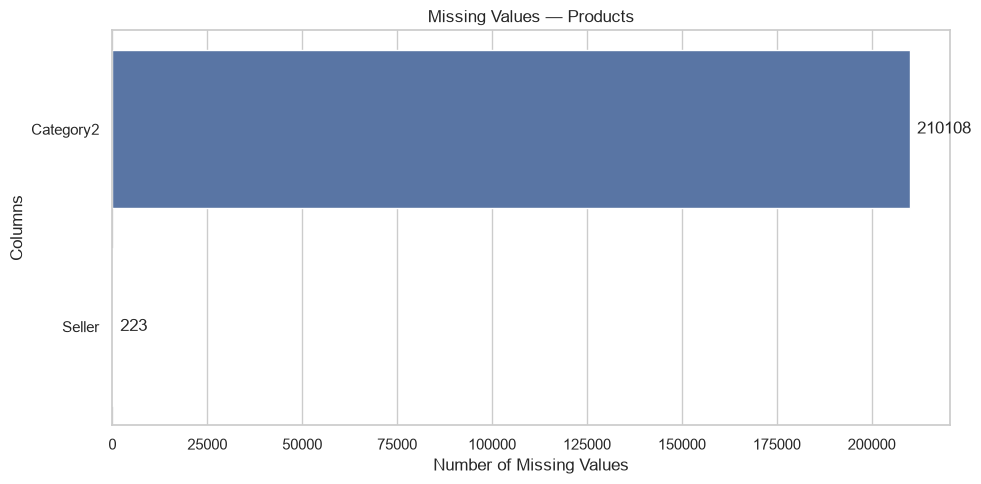

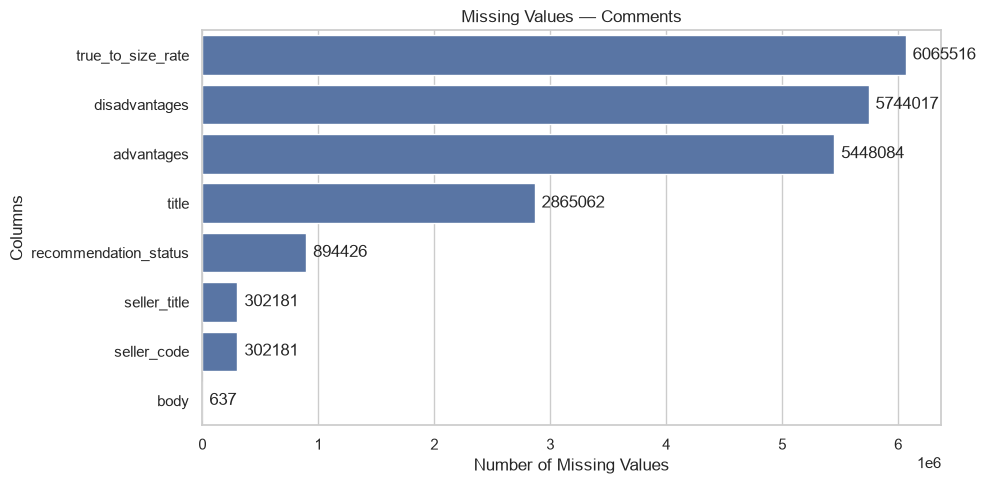

In [8]:
for name, df in [("Products", products), ("Comments", comments)]:
    missing = df.isnull().sum().sort_values(ascending=False)
    missing = missing[missing > 0].head(20)

    if len(missing):
        plt.figure(figsize=(10, 5))
        ax = sns.barplot(x=missing.values, y=missing.index)
        ax.bar_label(ax.containers[0], fmt="%.0f", padding=5)
        plt.title(f"Missing Values — {name}")
        plt.xlabel("Number of Missing Values")
        plt.ylabel("Columns")
        plt.tight_layout()
        plt.show()

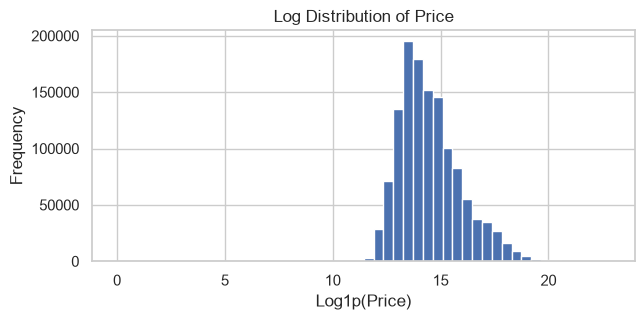

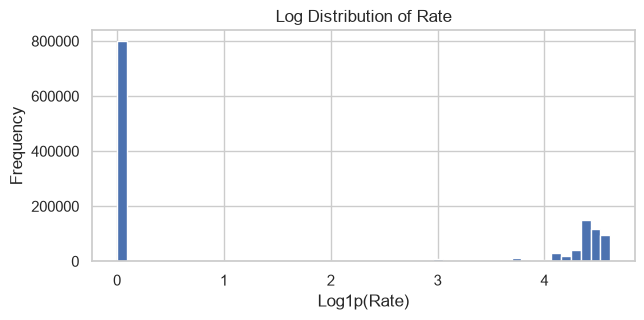

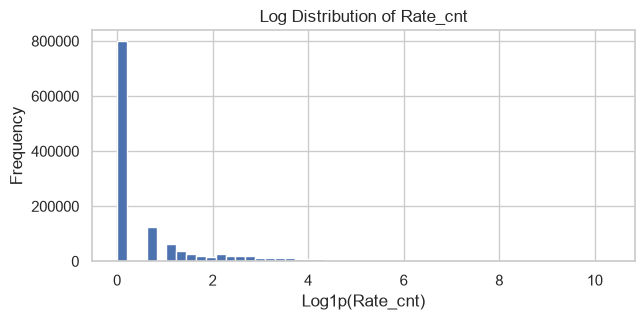

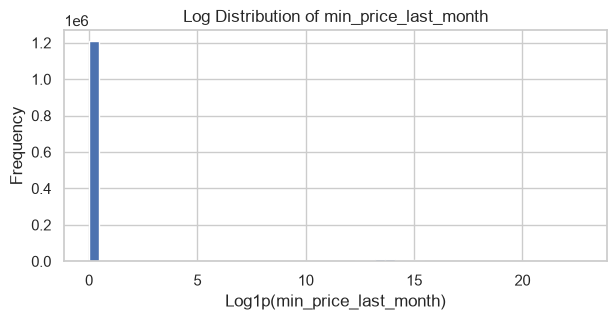

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# numeric columns
for col in ["Price", "Rate", "Rate_cnt", "min_price_last_month"]:
    if col in products:
        data = products[col].dropna()
        data_log = np.log1p(data)         
        data_log.plot(kind="hist", bins=50, figsize=(7, 3), title=f"Log Distribution of {col}")
        plt.xlabel(f"Log1p({col})")
        plt.show()

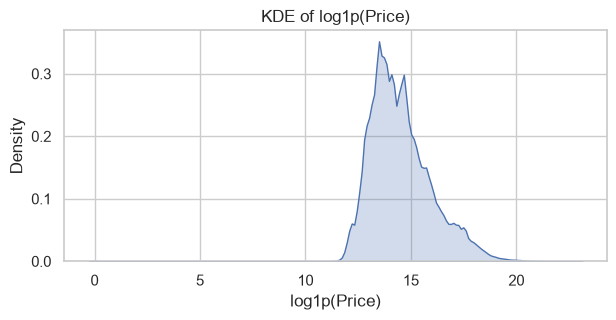

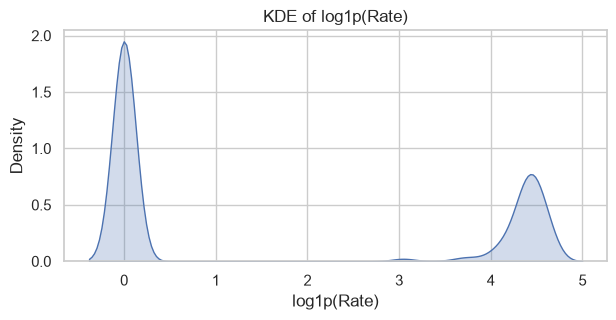

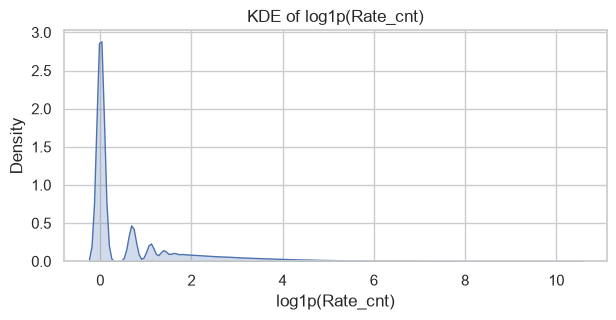

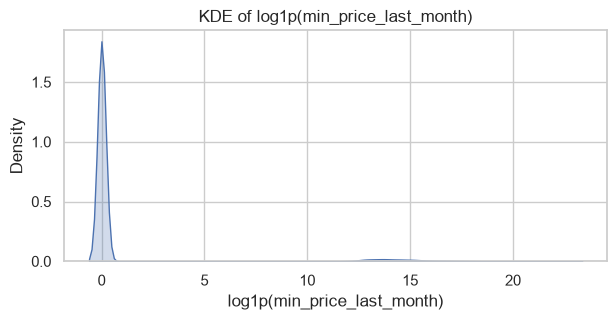

In [10]:

for col in ["Price", "Rate", "Rate_cnt", "min_price_last_month"]:
    if col in products:
        data = products[col].dropna()
        log_data = np.log1p(data)
        plt.figure(figsize=(7, 3))
        sns.kdeplot(log_data, fill=True)
        plt.title(f"KDE of log1p({col})")
        plt.xlabel(f"log1p({col})")
        plt.show()

In [11]:
# common categories and brands
for col in ["Category1", "Category2", "sub_category", "Brand"]:
    if col in products:
        print(f"Top values in {col}:")
        display(products[col].value_counts().head(15))

Top values in Category1:


Category1
اکسسوری زنانه و مردانه     95999
لباس زنانه                 93392
اسباب بازی                 92466
لباس مردانه                68178
اکسسوری زنانه              64470
اکسسوری مردانه             49383
دخترانه                    42931
دفتر و کاغذ و مقوا         42864
زیورآلات طلا زنانه         41098
کتاب چاپی غیر فارسی        39409
مراقبت پوست                29662
مواد غذایی                 28930
پسرانه                     27066
کتاب شعر و ادبیات          23345
برس‌ها و تجهیزات آرایشی    22749
Name: count, dtype: int64

Top values in Category2:


Category2
فکری و آموزشی                   46767
دفتر                            38459
زیورآلات زنانه و مردانه         35086
لباس دخترانه                    26752
لباس ورزشی زنانه                23009
جغجغه، عروسک و مدل              22846
لباس پسرانه                     22773
تی شرت مردانه                   21356
گردنبند طلا زنانه               20463
ساعت مردانه                     20212
زیورآلات زنانه                  19630
کاشی کاری                       19300
عینک زنانه و مردانه             19280
زیورآلات نقره زنانه             18774
برس ها و تجهیزات آرایشی صورت    15740
Name: count, dtype: int64

Top values in sub_category:


sub_category
clothe                     587946
book & stationary & art    343597
beauty                     168648
toys and kids              118635
rural goods                 40893
travel                      23777
Name: count, dtype: int64

Top values in Brand:


Brand
متفرقه           723590
لیردا             19378
الن نار           15392
خندالو            14169
اطلس آبی           9955
ترمه ۱             9527
کرابو              9055
27                 8396
کارنیلا            8083
اچ اند ام          7813
کارانس             7644
ناکسیگو            6875
اسمارا             6282
نقش نگار رضوی      5422
والار              5031
Name: count, dtype: int64

In [12]:
comments["rate"].value_counts()

rate
5.00       2398801
4.00       1515723
3.00        958799
0.00        529098
1.00        327662
            ...   
3.07             1
4.63             1
3.88             1
0.57             1
2500.00          1
Name: count, Length: 178, dtype: int64

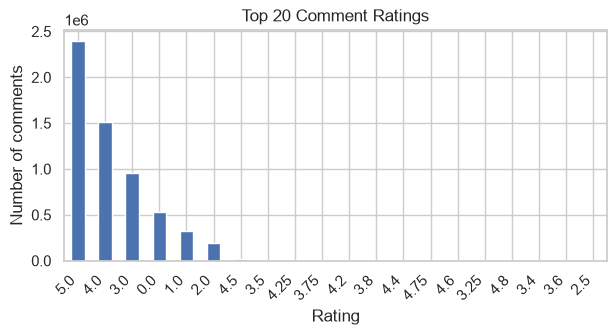

In [13]:
if "rate" in comments:
    # Get the top 20 most frequent ratings
    top_ratings = comments["rate"].value_counts().nlargest(20)
    
    top_ratings.plot(kind="bar", figsize=(7, 3), title="Top 20 Comment Ratings")
    plt.xlabel("Rating")
    plt.ylabel("Number of comments")
    # Rotate x-labels so they are readable
    plt.xticks(rotation=45, ha="right") 
    plt.show()

In [14]:
# Recommendation status and buyer status
for col in ["recommendation_status", "is_buyer"]:
    if col in comments:
        display(comments[col].value_counts(dropna=False).to_frame("count"))

,count
recommendation_status,
recommended,4162839
NaN,894426
no_idea,594121
not_recommended,504903


,count
is_buyer,
True,5854108
False,302181


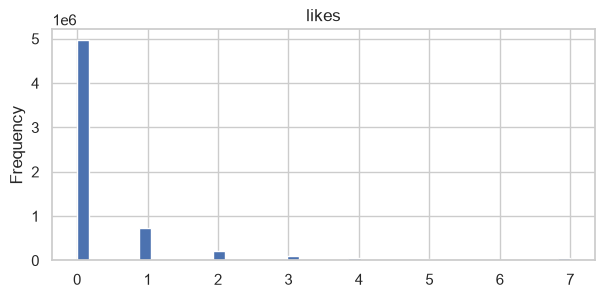

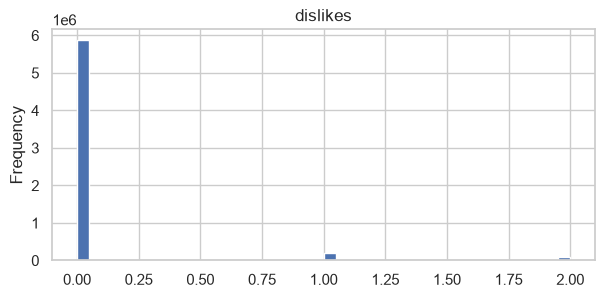

In [15]:
# Likes and dislikes
for col in ["likes", "dislikes"]:
    if col in comments:
        comments[col].dropna().clip(upper=comments[col].quantile(0.99)).plot(kind="hist", bins=40, figsize=(7, 3), title=col)
        plt.show()

In [16]:
comments["created_at"].value_counts()

created_at
18 خرداد 1402      17834
10 تیر 1402        13210
13 اسفند 1401      12549
31 خرداد 1402      12398
11 شهریور 1402     12235
                   ...  
18 آذر 1395            4
23 مهر 1395            4
16 آذر 1396            4
7 اردیبهشت 1396        4
23 تیر 1395            1
Name: count, Length: 2654, dtype: int64

In [17]:

def convert_date(date):
    try:
        day, month_name, year = str(date).split()

        months = {
            "فروردین": 1, "اردیبهشت": 2, "خرداد": 3,
            "تیر": 4, "مرداد": 5, "شهریور": 6,
            "مهر": 7, "آبان": 8, "آذر": 9,
            "دی": 10, "بهمن": 11, "اسفند": 12
        }
        
        jalali_date = jdatetime.date(int(year), months[month_name], int(day))
        return jalali_date.togregorian()

    except:
        return pd.NaT


comments["created_at"] = pd.to_datetime(comments["created_at"].apply(convert_date))




In [18]:
display(comments.head())

,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,2023-09-14,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,2020-07-06,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,2022-08-17,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,2021-03-18,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,2023-09-03,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN


Earliest date: 2016-07-13 00:00:00
Latest date: 2023-10-18 00:00:00


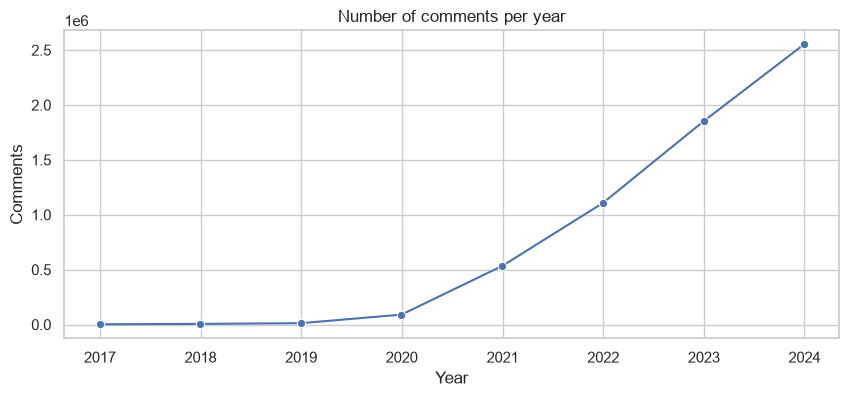

In [19]:


print("Earliest date:", comments["created_at"].min())
print("Latest date:", comments["created_at"].max())

yearly_comments = comments.set_index("created_at").resample("YE").size().reset_index(name="count")

plt.figure(figsize=(10, 4))
sns.lineplot(data=yearly_comments, x="created_at", y="count", marker="o" )
plt.title("Number of comments per year")
plt.ylabel("Comments")
plt.xlabel("Year")
plt.show()

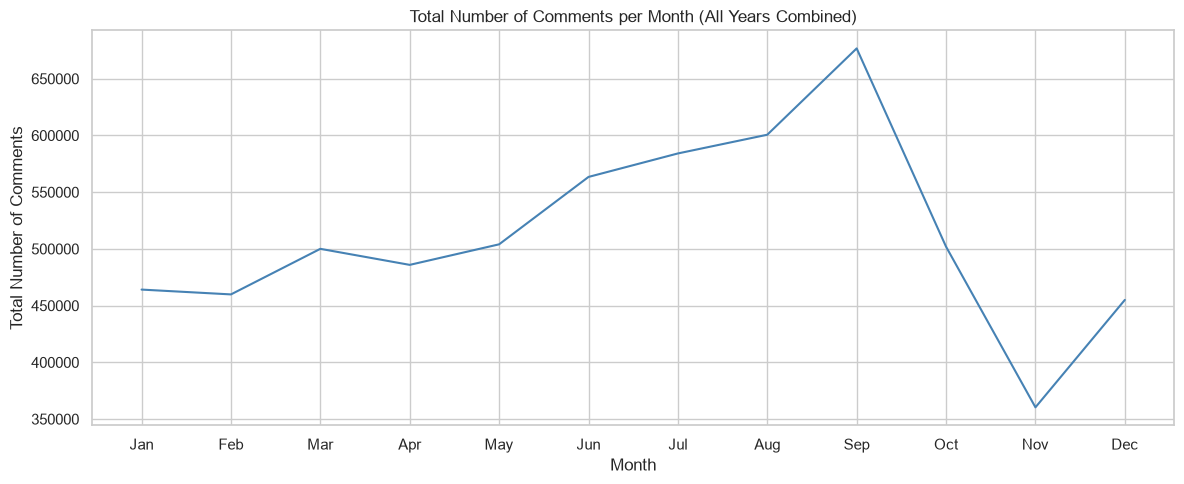

In [20]:

comments["month_num"] = comments["created_at"].dt.month
comments["month_name"] = comments["created_at"].dt.strftime("%b") 

monthly_agg = comments.groupby(["month_num", "month_name"]).size().reset_index(name="count").sort_values("month_num") 

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_agg, x="month_name", y="count", color="steelblue")
plt.title("Total Number of Comments per Month (All Years Combined)")
plt.xlabel("Month")
plt.ylabel("Total Number of Comments")
plt.tight_layout()
plt.show()

In [21]:


def clean_persian_text(value):
    if pd.isna(value):
        return ""
    text = str(value)
    text = text.replace("ي", "ی").replace("ك", "ک")
    text = re.sub(r"[\\u064B-\\u065F\\u0670\\u0640]", "", text)
    text = text.replace("\\u200f", "").replace("\\u200e", "")
    text = re.sub(r"\\s+", " ", text).strip()
    return text

for col in ["title_fa"]:
    if col in products:
        products[col + "_clean"] = products[col].apply(clean_persian_text)

for col in ["title", "body", "advantages", "disadvantages"]:
    if col in comments:
        comments[col + "_clean"] = comments[col].apply(clean_persian_text)

display(comments[[c for c in ["body", "body_clean"] if c in comments]].head(10))


,body,body_clean
0,به درد نمیخوره,به درد نمیخوره
1,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...
2,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...
3,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...
4,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...
5,قبلا هم استفاده کردم اگه بلد باشین کار کردن با...,قبلا هم استفاده کردم اگه بلد باشین کار کردن با...
6,خوبه,خوبه
7,خیلی به کارتون میاد قیمتشم مناسبه,خیلی به کارتون میاد قیمتشم مناسبه
8,دقیقا مطابق عکس بود,دقیقا مطابق عکس بود
9,برا حالت دادن با اسپری یا پودر عالیه,برا حالت دادن با اسپری یا پودر عالیه


In [22]:
for col in ["title_clean", "body_clean", "advantages_clean", "disadvantages_clean"]:
    if col in comments:
        comments[col + "_length"] = comments[col].str.len()
        print(col, "average character count:", comments[col + "_length"].mean())

title_clean average character count: 6.140171457187926
body_clean average character count: 48.1790106020039
advantages_clean average character count: 3.5564394394090337
disadvantages_clean average character count: 1.7119966265391375


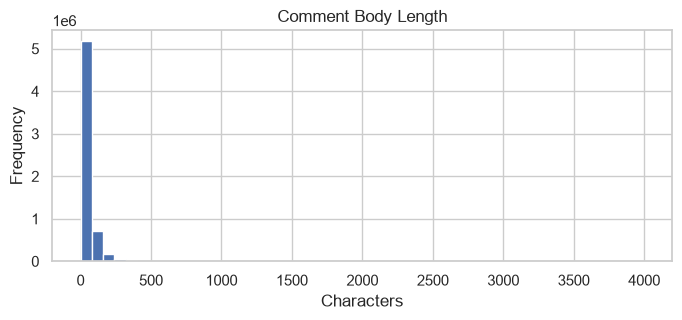

In [23]:
comments["body_length"] = comments["body_clean"].str.len()
comments["body_length"].plot(kind="hist", bins=50, figsize=(8, 3), title="Comment Body Length")
plt.xlabel("Characters")
plt.ylabel("Frequency")
plt.show()

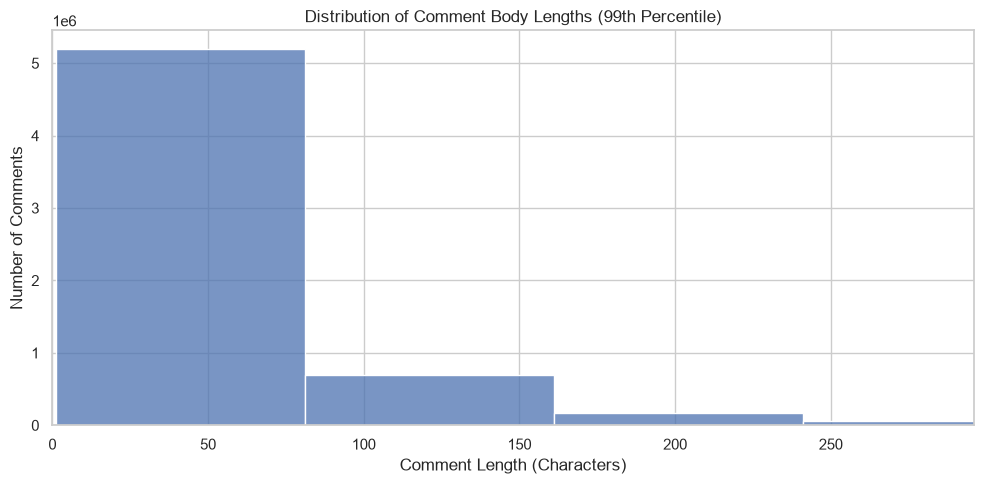

In [24]:
limit = comments["body_length"].quantile(0.99)
plt.figure(figsize=(10, 5))
sns.histplot(data=comments[comments["body_length"] > 0], x="body_length", bins=50)
plt.xlim(0, limit)
plt.title("Distribution of Comment Body Lengths (99th Percentile)")
plt.xlabel("Comment Length (Characters)")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()


In [25]:
comments.head()

,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate,month_num,month_name,title_clean,body_clean,advantages_clean,disadvantages_clean,title_clean_length,body_clean_length,advantages_clean_length,disadvantages_clean_length,body_length
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,2023-09-14,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN,9,Sep,پیشنهاد نمیشود,به درد نمیخوره,,,14,14,0,0,14
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,2020-07-06,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN,7,Jul,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,'تجربه جالبی بود برام '],'بسته بندی جالبی نداشت'],12,52,24,24,52
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,2022-08-17,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN,8,Aug,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,,,8,89,0,0,89
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,2021-03-18,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN,3,Mar,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,,,13,86,0,0,86
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,2023-09-03,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN,9,Sep,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,,,10,97,0,0,97


In [26]:
products.head()

,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category,title_fa_clean
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,False,0,beauty,آبسلانگ مدل s بسته 2 عددی
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,False,0,beauty,آبسلانگ مدل -1 بسته عددی
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,False,0,beauty,آبسلانگ مدل m مجموعه عددی
3,1912926,استند ابسلانگ مدل S01,78,25,آبسلانگ,NaN,متفرقه,1100000,بهراد طب بیدار,False,0,beauty,استند ابسلانگ مدل 1
4,6335462,آبسلانگ نوری تسلامد مدل All-in-One,84,25,آبسلانگ,NaN,تسلا مد,1530000,دیجی‌کالا,False,0,beauty,آبسلانگ نوری تسلامد مدل All-in-ne


In [27]:
products_clean = products.drop_duplicates().copy()
comments_clean = comments.drop_duplicates().copy()

In [28]:
print("Clean products:", products_clean.shape)
print("Clean comments:", comments_clean.shape)

Clean products: (960367, 13)
Clean comments: (6154971, 26)


In [29]:
products_clean = products_clean.drop_duplicates(subset="id", keep="first")
comments_clean = comments_clean.drop_duplicates(subset="id", keep="first")

In [30]:
print("Clean products:", products_clean.shape)
print("Clean comments:", comments_clean.shape)

Clean products: (948352, 13)
Clean comments: (6153060, 26)


In [31]:
products_for_join = products_clean.rename(columns={"id": "product_id"})
merged = comments_clean.merge(products_for_join, on="product_id", how="left", suffixes=("_comment", "_product"))

print("Merged data shape:", merged.shape)
print("Comments without product information:", merged["title_fa"].isna().sum() if "title_fa" in merged else "Check product columns")
display(merged.head())


Merged data shape: (6153060, 38)
Comments without product information: 0


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate,month_num,month_name,title_clean,body_clean,advantages_clean,disadvantages_clean,title_clean_length,body_clean_length,advantages_clean_length,disadvantages_clean_length,body_length,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category,title_fa_clean
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,2023-09-14,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN,9,Sep,پیشنهاد نمیشود,به درد نمیخوره,,,14,14,0,0,14,کتاب صوتی امپراطوری اپ اثر چاد مورتا,74,212,کتاب صوتی,NaN,نوین کتاب گویا,199000,دیجی‌کالا,False,0,book & stationary & art,کتاب صوتی امپراطوری اپ اثر چاد مورتا
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,2020-07-06,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN,7,Jul,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,'تجربه جالبی بود برام '],'بسته بندی جالبی نداشت'],12,52,24,24,52,کتاب صوتی امپراطوری اپ اثر چاد مورتا,74,212,کتاب صوتی,NaN,نوین کتاب گویا,199000,دیجی‌کالا,False,0,book & stationary & art,کتاب صوتی امپراطوری اپ اثر چاد مورتا
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,2022-08-17,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN,8,Aug,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,,,8,89,0,0,89,برس ریمل مدل LM02 مجموعه 2 عددی,84,587,برس‌ها و تجهیزات آرایشی,برس ها و تجهیزات آرایشی چشم و ابرو,متفرقه,79000,پینک لندشاپ,False,0,beauty,برس ریمل مدل 2 مجموعه 2 عددی
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,2021-03-18,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN,3,Mar,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,,,13,86,0,0,86,برس ریمل مدل MNP-03,82,465,برس‌ها و تجهیزات آرایشی,برس ها و تجهیزات آرایشی چشم و ابرو,متفرقه,80000,یانگوم,False,0,beauty,برس ریمل مدل -3
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,2023-09-03,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN,9,Sep,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,,,10,97,0,0,97,برس رنگ مو مدل 01,82,19,برس‌ها و تجهیزات آرایشی,تجهیزات رنگ مو,متفرقه,84100,گالری آرایشی به سیما,False,84100,beauty,برس رنگ مو مدل 1


In [32]:
merged.isna().sum()

id                                  0
title                         2863530
body                              637
created_at                          0
rate                                0
recommendation_status          894070
is_buyer                            0
product_id                          0
advantages                    5445249
disadvantages                 5741020
likes                               0
dislikes                            0
seller_title                   301979
seller_code                    301979
true_to_size_rate             6062337
month_num                           0
month_name                          0
title_clean                         0
body_clean                          0
advantages_clean                    0
disadvantages_clean                 0
title_clean_length                  0
body_clean_length                   0
advantages_clean_length             0
disadvantages_clean_length          0
body_length                         0
title_fa    

In [35]:
products_clean.to_csv(OUTPUT_FOLDER / "products_clean.csv", index=False)
comments_clean.to_csv(OUTPUT_FOLDER / "comments_clean.csv", index=False)
merged.to_csv(OUTPUT_FOLDER / "comments_products_merged.csv", index=False)